# NB06 - Reporting Layer
### Cross-Benefit Duplicate Drug Billing Detection

**Schema:** `cross_benefit_audit`<br>
**Tables created:** `member_risk_summary`, `molecule_risk_summary`, `plan_risk_summary`, `investigator_queue`<br>
**Depends on:** NB01, NB02, NB03, NB04, NB05

---

## What this notebook does

Builds the reporting layer from `risk_scored_pairs`. Output is organized around three audiences:

| Audience | Output | Key metric |
|---|---|---|
| Executive / audit committee | Aggregate financial exposure and detection efficiency | Total TP exposure, HIGH-tier precision |
| Program management | Per-molecule and per-plan breakdown | Precision and exposure by drug class |
| Investigator | Ranked referral queue with feature flags | risk_score, combined_cost, npi_match, dose_concordance |

### Tables written

| Table | Description |
|---|---|
| `member_risk_summary` | One row per member with HIGH-tier pairs; exposure and risk tier summary |
| `molecule_risk_summary` | Per-molecule detection precision, exposure, and feature flag rates |
| `plan_risk_summary` | Per-plan-type pair counts, precision, and financial exposure |
| `investigator_queue` | HIGH-tier candidate pairs ranked by risk_score with all feature flags |

## 0 - Setup

In [0]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

spark = SparkSession.builder.getOrCreate()

IN_TABLE     = "cross_benefit_audit.risk_scored_pairs"
OUT_MEMBER   = "cross_benefit_audit.member_risk_summary"
OUT_MOLECULE = "cross_benefit_audit.molecule_risk_summary"
OUT_PLAN     = "cross_benefit_audit.plan_risk_summary"
OUT_QUEUE    = "cross_benefit_audit.investigator_queue"

# Ground-truth denominator - matches seeded event count from NB02/NB03
TOTAL_SEEDED_EVENTS = 72

# Seeded counts by scenario type for completeness check in Section 6
SEEDED_COUNTS = {
    "EXACT_SAME_CODE": 20,
    "NEAR_DATE":       16,
    "QCODE_GAP":       18,
    "NEW_FORM_CROSS":  10,
    "DIFF_BIOSIM":      8,
}

print("Setup complete.")
print(f"Input  : {IN_TABLE}")
print(f"Outputs: {OUT_MEMBER}, {OUT_MOLECULE}, {OUT_PLAN}, {OUT_QUEUE}")

Setup complete.
Input  : cross_benefit_audit.risk_scored_pairs
Outputs: cross_benefit_audit.member_risk_summary, cross_benefit_audit.molecule_risk_summary, cross_benefit_audit.plan_risk_summary, cross_benefit_audit.investigator_queue


---
## 1 - Load tables

In [0]:
risk = spark.table(IN_TABLE)

print(f"risk_scored_pairs: {risk.count():,} rows")
print()
risk.printSchema()

risk_scored_pairs: 405 rows

root
 |-- rx_claim_id: string (nullable = true)
 |-- med_claim_id: string (nullable = true)
 |-- member_id: string (nullable = true)
 |-- rx_date: date (nullable = true)
 |-- med_date: date (nullable = true)
 |-- date_diff_days: integer (nullable = true)
 |-- rx_hcpcs: string (nullable = true)
 |-- med_hcpcs: string (nullable = true)
 |-- rx_molecule: string (nullable = true)
 |-- match_type: string (nullable = true)
 |-- confidence_score: double (nullable = true)
 |-- is_true_positive: boolean (nullable = true)
 |-- seed_event_id: string (nullable = true)
 |-- seed_scenario_type: string (nullable = true)
 |-- plan_type: string (nullable = true)
 |-- therapeutic_area: string (nullable = true)
 |-- prescriber_npi: string (nullable = true)
 |-- pharmacy_npi: string (nullable = true)
 |-- rendering_npi: string (nullable = true)
 |-- rx_cost: double (nullable = true)
 |-- med_allowed: double (nullable = true)
 |-- combined_cost: double (nullable = true)
 |-- rx

---
## 2 - Executive summary

In [0]:
total_pairs   = risk.count()
total_members = risk.select("member_id").distinct().count()

# Outcome counts
total_tp = risk.filter("is_true_positive = true").count()
total_fp = risk.filter("is_true_positive = false").count()

# Financial exposure
total_exposure = risk.agg(F.round(F.sum("combined_cost"), 2)).collect()[0][0]
tp_exposure    = (
    risk
    .filter("is_true_positive = true")
    .agg(F.round(F.sum("combined_cost"), 2))
    .collect()[0][0]
)

# HIGH-tier metrics
high_pairs     = risk.filter("risk_tier = 'HIGH'").count()
high_tp        = risk.filter("risk_tier = 'HIGH' AND is_true_positive = true").count()
high_fp        = high_pairs - high_tp
high_precision = high_tp / high_pairs if high_pairs > 0 else 0.0
high_recall    = high_tp / TOTAL_SEEDED_EVENTS

print("=" * 62)
print("Executive summary - Cross-benefit duplicate drug billing")
print("=" * 62)
print(f"  Candidate pairs flagged        : {total_pairs:,}")
print(f"  Unique members with flags      : {total_members:,}")
print(f"  True positives (confirmed)     : {total_tp}")
print(f"  False positives                : {total_fp}")
print(f"  Overall precision              : {total_tp / total_pairs:.1%}")
print(f"  Recall (all seeded events)     : {total_tp / TOTAL_SEEDED_EVENTS:.1%}")
print()
print(f"  Financial exposure - all pairs : ${total_exposure:,.2f}")
print(f"  TP exposure (confirmed dup.)   : ${tp_exposure:,.2f}")
print(f"  TP share of total exposure     : {tp_exposure / total_exposure:.1%}")
print()
print(f"  HIGH-tier pairs                : {high_pairs}")
print(f"  HIGH-tier TPs                  : {high_tp}")
print(f"  HIGH-tier FPs                  : {high_fp}")
print(f"  HIGH-tier precision            : {high_precision:.1%}")
print(f"  HIGH-tier recall               : {high_recall:.1%}")
print(f"  Pairs pruned by tier cutoff    : {total_pairs - high_pairs} ({(total_pairs - high_pairs) / total_pairs:.1%} of all pairs)")
print("=" * 62)

Executive summary - Cross-benefit duplicate drug billing
  Candidate pairs flagged        : 405
  Unique members with flags      : 136
  True positives (confirmed)     : 72
  False positives                : 333
  Overall precision              : 17.8%
  Recall (all seeded events)     : 100.0%

  Financial exposure - all pairs : $3,369,295.67
  TP exposure (confirmed dup.)   : $652,712.03
  TP share of total exposure     : 19.4%

  HIGH-tier pairs                : 232
  HIGH-tier TPs                  : 72
  HIGH-tier FPs                  : 160
  HIGH-tier precision            : 31.0%
  HIGH-tier recall               : 100.0%
  Pairs pruned by tier cutoff    : 173 (42.7% of all pairs)


---
## 3 - Molecule-level detection report

Aggregates all pairs (all tiers) by molecule. Precision is the fraction of pairs that are confirmed TPs.
Feature flag rates reflect how often each bonus fires across the pair population for that molecule.

In [0]:
mol_summary = (
    risk
    .groupBy("rx_molecule", "therapeutic_area")
    .agg(
        F.count("rx_claim_id").alias("pairs"),
        F.sum(F.col("is_true_positive").cast("integer")).alias("tp"),
        F.sum((~F.col("is_true_positive")).cast("integer")).alias("fp"),
        F.round(F.sum("combined_cost"), 2).alias("total_exposure"),
        F.round(
            F.sum(
                F.when(F.col("is_true_positive"), F.col("combined_cost")).otherwise(F.lit(0))
            ), 2
        ).alias("tp_exposure"),
        F.round(F.avg("risk_score"), 3).alias("avg_risk_score"),
        F.round(F.avg("npi_match"), 3).alias("npi_match_rate"),
        F.round(F.avg("dose_concordance_flag"), 3).alias("dose_concordance_rate"),
        F.round(F.avg("dual_cost_flag"), 3).alias("dual_cost_rate"),
    )
    .withColumn(
        "precision",
        F.round(F.col("tp") / F.col("pairs"), 3)
    )
    .withColumn(
        "tp_exposure_pct",
        F.round(F.col("tp_exposure") / F.col("total_exposure") * 100, 1)
    )
    .orderBy(F.desc("total_exposure"))
)

print("Per-molecule detection summary (all tiers):")
mol_summary.show(20, truncate=False)

Per-molecule detection summary (all tiers):
+-------------+----------------+-----+---+---+--------------+-----------+--------------+--------------+---------------------+--------------+---------+---------------+
|rx_molecule  |therapeutic_area|pairs|tp |fp |total_exposure|tp_exposure|avg_risk_score|npi_match_rate|dose_concordance_rate|dual_cost_rate|precision|tp_exposure_pct|
+-------------+----------------+-----+---+---+--------------+-----------+--------------+--------------+---------------------+--------------+---------+---------------+
|pembrolizumab|oncology        |75   |18 |57 |1430334.15    |336927.26  |0.89          |0.36          |0.28                 |1.0           |0.24     |23.6           |
|ocrelizumab  |neurology       |45   |7  |38 |1279687.44    |194942.78  |0.868         |0.2           |0.267                |1.0           |0.156    |15.2           |
|infliximab   |autoimmune      |46   |13 |33 |237940.64     |60920.64   |0.861         |0.326         |0.391             

---
## 4 - Plan-type exposure report

In [0]:
plan_summary = (
    risk
    .groupBy("plan_type")
    .agg(
        F.count("rx_claim_id").alias("pairs"),
        F.sum(F.col("is_true_positive").cast("integer")).alias("tp"),
        F.sum((~F.col("is_true_positive")).cast("integer")).alias("fp"),
        F.round(F.sum("combined_cost"), 2).alias("total_exposure"),
        F.round(
            F.sum(
                F.when(F.col("is_true_positive"), F.col("combined_cost")).otherwise(F.lit(0))
            ), 2
        ).alias("tp_exposure"),
    )
    .withColumn(
        "precision",
        F.round(F.col("tp") / F.col("pairs"), 3)
    )
    .withColumn(
        "tp_exposure_pct",
        F.round(F.col("tp_exposure") / F.col("total_exposure") * 100, 1)
    )
    .orderBy(F.desc("total_exposure"))
)

print("Per-plan-type summary (all tiers):")
plan_summary.show(truncate=False)

Per-plan-type summary (all tiers):
+---------+-----+---+---+--------------+-----------+---------+---------------+
|plan_type|pairs|tp |fp |total_exposure|tp_exposure|precision|tp_exposure_pct|
+---------+-----+---+---+--------------+-----------+---------+---------------+
|GRP-1808 |7    |1  |6  |207287.03     |29361.8    |0.143    |14.2           |
|GRP-4730 |10   |3  |7  |184535.67     |53394.13   |0.3      |28.9           |
|GRP-5570 |8    |2  |6  |155972.73     |41617.41   |0.25     |26.7           |
|GRP-9240 |5    |1  |4  |139949.26     |25948.45   |0.2      |18.5           |
|GRP-8607 |5    |2  |3  |139689.15     |54519.74   |0.4      |39.0           |
|GRP-6476 |4    |0  |4  |115629.05     |0.0        |0.0      |0.0            |
|GRP-1924 |6    |0  |6  |112744.9      |0.0        |0.0      |0.0            |
|GRP-4183 |6    |1  |5  |111706.67     |17176.89   |0.167    |15.4           |
|GRP-7484 |4    |1  |3  |106242.22     |27784.42   |0.25     |26.2           |
|GRP-7180 |5    |

---
## 5 - Member-level risk roster

One row per member that has at least one HIGH-tier pair.
In production this drives case assignment - members with the highest
exposure and confirmed TP signal are prioritized.

In [0]:
member_summary = (
    risk
    .filter("risk_tier = 'HIGH'")
    .groupBy("member_id")
    .agg(
        F.count("rx_claim_id").alias("high_tier_pairs"),
        F.sum(F.col("is_true_positive").cast("integer")).alias("confirmed_tp"),
        F.sum((~F.col("is_true_positive")).cast("integer")).alias("fp_pairs"),
        F.round(F.sum("combined_cost"), 2).alias("high_tier_exposure"),
        F.round(
            F.sum(
                F.when(F.col("is_true_positive"), F.col("combined_cost")).otherwise(F.lit(0))
            ), 2
        ).alias("tp_exposure"),
        F.round(F.max("risk_score"), 2).alias("max_risk_score"),
        F.round(F.avg("npi_match"), 2).alias("npi_match_rate"),
        # collect_set ignores nulls - FP pairs have null seed_scenario_type
        F.collect_set("seed_scenario_type").alias("scenario_types_found"),
    )
    .orderBy(F.desc("high_tier_exposure"))
)

member_count = member_summary.count()
print(f"Members with HIGH-tier pairs: {member_count}")
print()
print("Top 20 by HIGH-tier exposure:")
member_summary.show(20, truncate=False)

Members with HIGH-tier pairs: 104

Top 20 by HIGH-tier exposure:
+----------+---------------+------------+--------+------------------+-----------+--------------+--------------+--------------------------------------------+
|member_id |high_tier_pairs|confirmed_tp|fp_pairs|high_tier_exposure|tp_exposure|max_risk_score|npi_match_rate|scenario_types_found                        |
+----------+---------------+------------+--------+------------------+-----------+--------------+--------------+--------------------------------------------+
|MBR-000149|5              |1           |4       |147276.5          |29361.8    |1.0           |0.2           |[EXACT_SAME_CODE]                           |
|MBR-000110|7              |3           |4       |130902.52         |53394.13   |1.0           |0.43          |[NEW_FORM_CROSS, NEAR_DATE, EXACT_SAME_CODE]|
|MBR-000181|6              |2           |4       |120039.43         |41617.41   |1.0           |0.33          |[NEAR_DATE, EXACT_SAME_CODE]           

---
## 6 - Scenario detection completeness

For each seeded scenario: unique events recovered, average confidence and risk scores,
and total TP financial exposure. All five scenario types should appear here;
any scenario with fewer events found than seeded is a detection gap.

In [0]:
# Per scenario - unique events found, pair counts, avg scores, and exposure
scenario_stats = (
    risk
    .filter("is_true_positive = true")
    .groupBy("seed_scenario_type", "match_type")
    .agg(
        F.countDistinct("seed_event_id").alias("unique_events_found"),
        F.count("rx_claim_id").alias("tp_pairs"),
        F.round(F.avg("confidence_score"), 3).alias("avg_confidence"),
        F.round(F.avg("risk_score"), 3).alias("avg_risk_score"),
        F.round(F.avg("combined_cost"), 2).alias("avg_tp_exposure"),
        F.round(F.sum("combined_cost"), 2).alias("total_tp_exposure"),
    )
    .orderBy("seed_scenario_type")
)

print("Scenario detection breakdown (TP pairs only):")
scenario_stats.show(truncate=False)

# Completeness check: events found vs events seeded per scenario
found_by_scenario = (
    risk
    .filter("is_true_positive = true")
    .groupBy("seed_scenario_type")
    .agg(F.countDistinct("seed_event_id").alias("found"))
    .toPandas()
)

print("Completeness check:")
for _, row in found_by_scenario.iterrows():
    scenario = row["seed_scenario_type"]
    found    = int(row["found"])
    seeded   = SEEDED_COUNTS.get(scenario, "?")
    status   = "OK" if found == seeded else "MISS"
    print(f"  [{status}] {scenario:<20}: {found}/{seeded}")

Scenario detection breakdown (TP pairs only):
+------------------+----------+-------------------+--------+--------------+--------------+---------------+-----------------+
|seed_scenario_type|match_type|unique_events_found|tp_pairs|avg_confidence|avg_risk_score|avg_tp_exposure|total_tp_exposure|
+------------------+----------+-------------------+--------+--------------+--------------+---------------+-----------------+
|DIFF_BIOSIM       |DIFF_CODE |8                  |8       |0.8           |1.0           |1811.04        |14488.3          |
|EXACT_SAME_CODE   |SAME_CODE |20                 |20      |1.0           |1.0           |10924.97       |218499.3         |
|NEAR_DATE         |SAME_CODE |16                 |16      |0.9           |1.0           |10992.89       |175886.29        |
|NEW_FORM_CROSS    |DIFF_CODE |10                 |10      |0.73          |0.99          |19865.29       |198652.88        |
|QCODE_GAP         |DIFF_CODE |18                 |18      |0.761         |0.97

---
## 7 - Investigator referral queue

HIGH-tier candidate pairs ranked by risk_score descending, then combined_cost descending.
This is the working list for SIU or payment integrity investigators.
In production, `is_true_positive` and `seed_scenario_type` are not available;
they are included here because this is a validation dataset.

In [0]:
QUEUE_COLS = [
    # identifiers
    "rx_claim_id", "med_claim_id", "member_id",
    # dates
    "rx_date", "med_date", "date_diff_days",
    # drug
    "rx_hcpcs", "med_hcpcs", "rx_molecule",
    # matching
    "match_type", "confidence_score",
    # scoring
    "risk_score", "risk_tier",
    # feature flags
    "npi_match", "dual_cost_flag", "dose_concordance_flag",
    # financials
    "rx_cost", "med_allowed", "combined_cost",
    # provider NPIs
    "prescriber_npi", "rendering_npi",
    # dose reconciliation detail
    "rx_qty", "med_units", "median_billunits", "concordance_ratio",
    # ground truth (synthetic data only)
    "is_true_positive", "seed_scenario_type",
]

investigator_queue = (
    risk
    .filter("risk_tier = 'HIGH'")
    .select(QUEUE_COLS)
    .orderBy(F.desc("risk_score"), F.desc("combined_cost"))
)

queue_count = investigator_queue.count()
print(f"Investigator referral queue: {queue_count} pairs (HIGH tier)")
print()
print("Top 10 pairs by risk score:")
investigator_queue.show(10, truncate=True)

Investigator referral queue: 232 pairs (HIGH tier)

Top 10 pairs by risk score:
+-----------------+------------------+----------+----------+----------+--------------+--------+---------+-----------+----------+----------------+----------+---------+---------+--------------+---------------------+--------+-----------+-------------+--------------+-------------+---------+---------+----------------+-----------------+----------------+------------------+
|      rx_claim_id|      med_claim_id| member_id|   rx_date|  med_date|date_diff_days|rx_hcpcs|med_hcpcs|rx_molecule|match_type|confidence_score|risk_score|risk_tier|npi_match|dual_cost_flag|dose_concordance_flag| rx_cost|med_allowed|combined_cost|prescriber_npi|rendering_npi|   rx_qty|med_units|median_billunits|concordance_ratio|is_true_positive|seed_scenario_type|
+-----------------+------------------+----------+----------+----------+--------------+--------+---------+-----------+----------+----------------+----------+---------+---------+------

---
## 8 - Figures

### Figure 1 - HIGH-tier pair volume and TP exposure by molecule

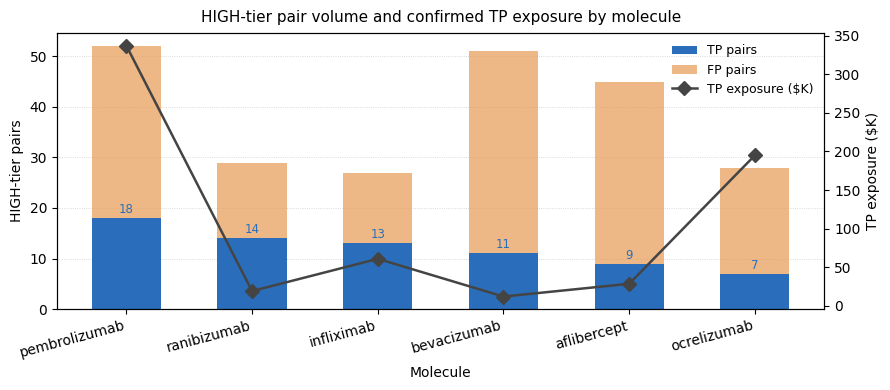

In [0]:
# Aggregate HIGH-tier pairs by molecule for figure 1
mol_high_pd = (
    risk
    .filter("risk_tier = 'HIGH'")
    .groupBy("rx_molecule")
    .agg(
        F.sum(F.col("is_true_positive").cast("integer")).alias("tp"),
        F.sum((~F.col("is_true_positive")).cast("integer")).alias("fp"),
        F.round(
            F.sum(
                F.when(F.col("is_true_positive"), F.col("combined_cost")).otherwise(F.lit(0))
            ) / 1000, 1
        ).alias("tp_exposure_k"),
    )
    .orderBy(F.desc("tp"))
    .toPandas()
)

fig, ax1 = plt.subplots(figsize=(9, 4))
ax2 = ax1.twinx()

x     = np.arange(len(mol_high_pd))
width = 0.55

bars_tp = ax1.bar(
    x, mol_high_pd["tp"], width,
    label="TP pairs", color="#2a6ebb", zorder=2
)
bars_fp = ax1.bar(
    x, mol_high_pd["fp"], width,
    bottom=mol_high_pd["tp"],
    label="FP pairs", color="#e8a05c", alpha=0.75, zorder=2
)
line = ax2.plot(
    x, mol_high_pd["tp_exposure_k"], "D-",
    color="#444444", label="TP exposure ($K)",
    linewidth=1.8, markersize=7, zorder=3
)

ax1.set_xticks(x)
ax1.set_xticklabels(mol_high_pd["rx_molecule"], fontsize=10, rotation=15, ha="right")
ax1.set_ylabel("HIGH-tier pairs", fontsize=10)
ax1.set_xlabel("Molecule", fontsize=10)
ax2.set_ylabel("TP exposure ($K)", fontsize=10)
ax1.set_title("HIGH-tier pair volume and confirmed TP exposure by molecule", fontsize=11, pad=8)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, fontsize=9, frameon=False, loc="upper right")
ax1.grid(axis="y", linestyle=":", linewidth=0.6, alpha=0.6)

# Label TP count above each stacked bar
for bar in bars_tp:
    h = bar.get_height()
    if h > 0:
        ax1.text(
            bar.get_x() + bar.get_width() / 2, h + 0.4,
            str(int(h)),
            ha="center", va="bottom", fontsize=8.5, color="#2a6ebb"
        )

plt.tight_layout()
display(fig)
plt.close()

### Figure 2 - TP exposure concentration across members

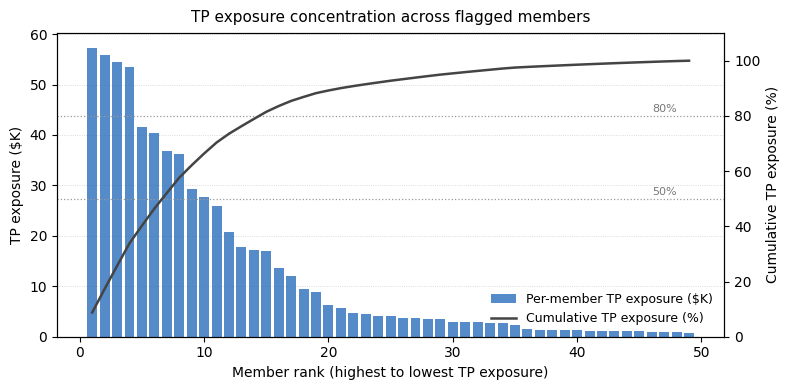

Top 7 members (14% of flagged) account for 50% of TP exposure.
Top 15 members (31% of flagged) account for 80% of TP exposure.


In [0]:
# TP exposure per member - confirmed TP pairs only - sorted highest to lowest
member_exp_pd = (
    risk
    .filter("is_true_positive = true")
    .groupBy("member_id")
    .agg(F.round(F.sum("combined_cost"), 2).alias("tp_exposure"))
    .orderBy(F.desc("tp_exposure"))
    .toPandas()
)

member_exp_pd["cumulative_exposure"] = member_exp_pd["tp_exposure"].cumsum()
member_exp_pd["cumulative_pct"]      = (
    member_exp_pd["cumulative_exposure"] / member_exp_pd["tp_exposure"].sum() * 100
)
member_exp_pd["rank"] = range(1, len(member_exp_pd) + 1)

# Annotate: how many members account for 50% and 80% of TP exposure
rank_50 = int((member_exp_pd["cumulative_pct"] < 50).sum()) + 1
rank_80 = int((member_exp_pd["cumulative_pct"] < 80).sum()) + 1

fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()

ax1.bar(
    member_exp_pd["rank"],
    member_exp_pd["tp_exposure"] / 1000,
    color="#2a6ebb", alpha=0.8, label="Per-member TP exposure ($K)", zorder=2
)
ax2.plot(
    member_exp_pd["rank"],
    member_exp_pd["cumulative_pct"],
    color="#444444", linewidth=1.8, label="Cumulative TP exposure (%)", zorder=3
)

# Reference lines at 50% and 80%
ax2.axhline(50, color="#999999", linestyle=":", linewidth=0.9)
ax2.axhline(80, color="#999999", linestyle=":", linewidth=0.9)
ax2.text(len(member_exp_pd) * 0.98, 51.5, "50%", ha="right", fontsize=8, color="#777777")
ax2.text(len(member_exp_pd) * 0.98, 81.5, "80%", ha="right", fontsize=8, color="#777777")

ax1.set_xlabel("Member rank (highest to lowest TP exposure)", fontsize=10)
ax1.set_ylabel("TP exposure ($K)", fontsize=10)
ax2.set_ylabel("Cumulative TP exposure (%)", fontsize=10)
ax2.set_ylim(0, 110)
ax1.set_title("TP exposure concentration across flagged members", fontsize=11, pad=8)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, fontsize=9, frameon=False, loc="lower right")
ax1.grid(axis="y", linestyle=":", linewidth=0.6, alpha=0.6)

plt.tight_layout()
display(fig)
plt.close()

print(f"Top {rank_50} members ({rank_50 / len(member_exp_pd):.0%} of flagged) account for 50% of TP exposure.")
print(f"Top {rank_80} members ({rank_80 / len(member_exp_pd):.0%} of flagged) account for 80% of TP exposure.")

---
## 9 - Write output tables

In [0]:
(
    member_summary.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(OUT_MEMBER)
)
print(f"Written: {OUT_MEMBER} ({spark.table(OUT_MEMBER).count():,} rows)")

(
    mol_summary.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(OUT_MOLECULE)
)
print(f"Written: {OUT_MOLECULE} ({spark.table(OUT_MOLECULE).count():,} rows)")

(
    plan_summary.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(OUT_PLAN)
)
print(f"Written: {OUT_PLAN} ({spark.table(OUT_PLAN).count():,} rows)")

(
    investigator_queue.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(OUT_QUEUE)
)
print(f"Written: {OUT_QUEUE} ({spark.table(OUT_QUEUE).count():,} rows)")

Written: cross_benefit_audit.member_risk_summary (104 rows)
Written: cross_benefit_audit.molecule_risk_summary (6 rows)
Written: cross_benefit_audit.plan_risk_summary (135 rows)
Written: cross_benefit_audit.investigator_queue (232 rows)


---
## 10 - Summary

### Tables written

| Table | Rows | Key fields |
|---|---|---|
| `member_risk_summary` | varies | member_id, high_tier_pairs, confirmed_tp, high_tier_exposure, max_risk_score |
| `molecule_risk_summary` | 6 | rx_molecule, tp, fp, precision, total_exposure, npi_match_rate, dose_concordance_rate |
| `plan_risk_summary` | varies | plan_type, tp, fp, precision, total_exposure |
| `investigator_queue` | 232 | risk_score, risk_tier, npi_match, dose_concordance_flag, dual_cost_flag, concordance_ratio |

### Full pipeline

| Notebook | Output table | Purpose |
|---|---|---|
| NB01 | target_hcpcs_crosswalk | CMS ASP molecule identity layer |
| NB02 | pharmacy_claims | Synthetic PBM claims (552 total, 72 seeded) |
| NB03 | medical_claims | Synthetic medical claims (752 total, 72 seeded) |
| NB04 | candidate_duplicate_pairs | Two-pass matching engine (405 pairs, 100% recall) |
| NB05 | risk_scored_pairs | NPI + dose + cost risk stratification |
| NB06 | member/molecule/plan summaries, investigator_queue | Reporting layer |

### Portfolio argument

The detection system demonstrates three separable contributions:

1. **Molecule bridge (NB04)**: surfaces 36 additional true positives that a naive HCPCS matcher misses. QCODE_GAP, NEW_FORM_CROSS, and DIFF_BIOSIM scenarios are invisible without the crosswalk translation layer.

2. **Risk stratification (NB05)**: concentrates all 72 confirmed duplicates into the HIGH tier at 31% precision vs 17.8% flat. NPI co-location fires at 100% for TPs and 12% for FPs; dose concordance TP median ratio is 1.011 vs FP median 0.062.

3. **Investigator efficiency (NB06)**: the HIGH-tier queue contains $652K in confirmed duplicate exposure across 232 candidate pairs. Working only the HIGH tier reduces investigator volume by 43% relative to reviewing all pairs with zero recall loss.

---